# ISS Heart — Benchmark Against Existing Alignment Methods (Fig 3d–f, S8)

The unimodal (RNA–RNA) benchmark of the SAME paper on two near-serial ISS sections of a 6.5 post-conception-week
human embryonic heart: SAME against eight published spatial alignment methods, all starting from the same
image-based (VALIS) initial alignment.

| Panel | Content |
|---|---|
| Fig 3d | Cell type matches per method |
| Fig 3e | Method summary: required inputs, transform, and change in cell type (CT) and cell neighborhood (CN) matches over the baseline |
| Fig 3f | Query cells before alignment and after PASTE2, GPSA, STAlign and SAME |
| Fig S8a,b | Cell neighborhoods on the template and query sections |
| Fig S8c | Cell neighborhood matches per method |

The SAME runs themselves (Fig 3a–c, S3–S7) are in
[`examples/heart/reproduce_figures.ipynb`](../../examples/heart/reproduce_figures.ipynb). The notebooks that ran each
competing method are in [`methods/`](methods/) (see [`../README.md`](../README.md)); this notebook only scores their
aligned outputs.

## Evaluation

Each method returns positions for the query cells in the template's frame; SAME instead assigns each matched query cell
to a template cell. Every method is scored in the same way:

1. **One-to-one assignment.** Aligned query cells are assigned to template cells with the Hungarian algorithm on
   Euclidean distance; pairs more than 100 registration units apart are not allowed.
2. **Cell type (CT) matches**: percentage of the query cells in a method's output whose assigned template cell has
   the same cell type (the eight cell types of the original publication). Query cells with no template cell within
   range count as mismatches.
3. **Cell neighborhood (CN) matches**: the same score with cell-neighborhood labels instead of cell types. A cell's
   neighborhood is the cell-type composition of its five nearest neighbours (scimap `spatial_count`, kNN = 6
   including the cell itself), clustered into six neighborhoods by one k-means model fitted on both sections.

The baseline is the initial image-based alignment.

### Requirements

Download `SAME_benchmarks_data.zip` (aligned outputs of every method) from the SAME Zenodo record,
<https://zenodo.org/records/19056915> (latest version), and unzip it inside `benchmarks/`, which creates
`benchmarks/heart/data/`. Run this notebook from `benchmarks/heart/`. SAME itself is not needed. Versions used:

```bash
pip install "scanpy==1.11.4" "anndata==0.10.9" "numpy==1.26.4" "scipy==1.16.2" "pandas==2.3.2" \
    "scikit-learn==1.9.1" "matplotlib==3.10.6" "jinja2==3.1.6"
```

Runtime: under a minute on a laptop.

## Setup

In [1]:
import warnings
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy
import sklearn
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.neighbors import BallTree

warnings.filterwarnings('ignore', category=FutureWarning)

NOTEBOOK_DIR = Path('.').resolve()
DATA_DIR = NOTEBOOK_DIR / 'data'
FIG_DIR = NOTEBOOK_DIR / 'figures'
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'DejaVu Sans'],
                     'svg.fonttype': 'none', 'pdf.fonttype': 42, 'font.size': 8})

print(f'scanpy {sc.__version__} | anndata {ad.__version__} | numpy {np.__version__} | scipy {scipy.__version__} | '
      f'pandas {pd.__version__} | scikit-learn {sklearn.__version__}')

scanpy 1.11.4 | anndata 0.10.9 | numpy 1.26.4 | scipy 1.16.2 | pandas 2.3.2 | scikit-learn 1.9.1


In [2]:
MAX_DIST = 100       # largest query-template distance allowed in the assignment (registration units)
KNN = 6              # neighbours per cell for the neighborhood composition (including the cell itself)
N_NEIGHBORHOODS = 6
SEED = 2025

# file tag, method type, transform, and whether the method needs expression / cell types as input
METHODS = pd.DataFrame([
    ('Baseline',  'input',     'Image-based',       'Elastic',       False, False),
    ('SAME',      'SAME',      'This work',         'Space-tearing', False, True),
    ('STAlign',   'STAlign',   'Density-based',     'Diffeomorphic', True,  False),
    ('STIM',      'STIM',      'Density-based',     'Affine',        True,  False),
    ('CAST',      'CAST',      'GCN',               'Elastic',       True,  False),
    ('SPACEL',    'SPACEL',    'GCN',               'Rigid',         False, True),
    ('STAligner', 'STAligner', 'GCN',               'Rigid',         True,  True),
    ('GPSA',      'GPSA',      'Gaussian Process',  'Elastic',       True,  False),
    ('PASTE2',    'PASTE2',    'Optimal Transport', 'Affine',        True,  False),
    ('ST-GEARS',  'STGEARS',   'Optimal Transport', 'Elastic',       True,  True),
], columns=['method', 'tag', 'type', 'transform', 'expression', 'cell_types']).set_index('method')

## 1. Input sections

`query_input.h5ad` and `ref_input.h5ad` hold the query and template sections after the initial image-based
alignment (`obsm['X_spatial']`), with each cell's original coordinates (`spot_x`, `spot_y`) and cell type.

In [3]:
query_in = ad.read_h5ad(DATA_DIR / 'query_input.h5ad')
template_in = ad.read_h5ad(DATA_DIR / 'ref_input.h5ad')
for a in (query_in, template_in):
    a.obs_names = a.obs_names.astype(str)
print(f'query: {query_in.n_obs} cells | template: {template_in.n_obs} cells | '
      f'cell types: {template_in.obs["CellType"].nunique()}')

query: 3184 cells | template: 3801 cells | cell types: 8


## 2. Cell neighborhoods

Neighborhood compositions are computed on each section's own coordinates, so they do not depend on any alignment.
This reimplements scimap's `spatial_count` with the same neighbour search (scikit-learn `BallTree`) and gives the
labels used in the paper.

In [4]:
def neighborhood_composition(xy, cell_type, categories, knn=KNN):
    """Fraction of each cell type among a cell's knn - 1 nearest neighbours
    (scimap `sm.tl.spatial_count(method='knn', knn=knn)`, which counts the cell itself as its first neighbour)."""
    nbrs = BallTree(xy, leaf_size=2).query(xy, k=knn, return_distance=False)[:, 1:]  # drop the cell itself
    types = np.asarray(cell_type, dtype=str)[nbrs]
    counts = np.stack([(types == c).sum(1) for c in categories], axis=1)
    return counts / counts.sum(1, keepdims=True)


categories = np.union1d(template_in.obs['CellType'].astype(str), query_in.obs['CellType'].astype(str))
comp = {name: neighborhood_composition(a.obs[['spot_x', 'spot_y']].to_numpy(float), a.obs['CellType'], categories)
        for name, a in (('template', template_in), ('query', query_in))}

# one k-means model fitted on both sections, so labels are comparable across them
kmeans = KMeans(n_clusters=N_NEIGHBORHOODS, init='random', n_init=10, max_iter=1000, random_state=SEED)
kmeans.fit(np.vstack([comp['template'], comp['query']]))
neighborhood = {'template': pd.Series(kmeans.predict(comp['template']).astype(str), index=template_in.obs_names),
                'query': pd.Series(kmeans.predict(comp['query']).astype(str), index=query_in.obs_names)}
pd.DataFrame({k: v.value_counts().sort_index() for k, v in neighborhood.items()}).rename_axis('neighborhood')

,template,query
neighborhood,,
0,1311,1165
1,842,245
2,722,1009
3,245,209
4,567,382
5,114,174


## 3. Score every method

For each method, `query_<method>.h5ad` / `ref_<method>.h5ad` hold the aligned query and template cells, with the
aligned positions in `obsm['X_<method>_spatial']`.

In [5]:
def hungarian_pairs(query_xy, template_xy, max_dist=MAX_DIST):
    """One-to-one assignment minimising the total distance; pairs farther apart than max_dist are disallowed.
    Returns the assigned (query, template) index pairs for query cells with at least one template cell in range."""
    cost = np.linalg.norm(query_xy[:, None, :] - template_xy[None, :, :], axis=2)
    cost[cost > max_dist] = 1e9
    qi, ti = linear_sum_assignment(cost)
    keep = cost.min(axis=1)[qi] <= max_dist
    return qi[keep], ti[keep]


def load_method(tag):
    """Aligned query and template AnnData of one method, and the obsm key with its aligned positions."""
    q, t = ad.read_h5ad(DATA_DIR / f'query_{tag}.h5ad'), ad.read_h5ad(DATA_DIR / f'ref_{tag}.h5ad')
    for a in (q, t):
        a.obs_names = a.obs_names.astype(str)
        if tag == 'STAligner':  # STAligner appends the section name to cell IDs
            a.obs_names = a.obs_names.str.split('_').str[0]
    return q, t, ('X_spatial' if tag == 'input' else f'X_{tag}_spatial')


rows, aligned_xy = [], {}
for method, tag in METHODS['tag'].items():
    q, t, key = load_method(tag)
    q_xy, t_xy = np.asarray(q.obsm[key], float), np.asarray(t.obsm[key], float)
    qi, ti = hungarian_pairs(q_xy, t_xy)
    ct = q.obs['CellType'].astype(str).to_numpy()[qi] == t.obs['CellType'].astype(str).to_numpy()[ti]
    cn = (neighborhood['query'].loc[q.obs_names].to_numpy()[qi]
          == neighborhood['template'].loc[t.obs_names].to_numpy()[ti])
    rows.append({'method': method, 'query cells': q.n_obs, 'assigned': len(qi),
                 'CT matches (%)': 100 * ct.sum() / q.n_obs, 'CN matches (%)': 100 * cn.sum() / q.n_obs})
    aligned_xy[method] = q_xy

scores = pd.DataFrame(rows).set_index('method')
scores['Δ CT'] = scores['CT matches (%)'] - scores.loc['Baseline', 'CT matches (%)']
scores['Δ CN'] = scores['CN matches (%)'] - scores.loc['Baseline', 'CN matches (%)']
scores.sort_values('CT matches (%)', ascending=False).round(2)

,query cells,assigned,CT matches (%),CN matches (%),Δ CT,Δ CN
method,,,,,,
SAME,3162,3162,71.60,67.84,13.87,1.91
STAlign,3184,3184,60.24,67.90,2.51,1.98
Baseline,3184,3184,57.73,65.92,0.00,0.00
STIM,3184,3184,57.44,65.36,-0.28,-0.57
CAST,3184,3184,55.62,64.26,-2.10,-1.66
SPACEL,3184,3184,55.53,64.13,-2.20,-1.79
STAligner,3184,3184,54.49,64.01,-3.23,-1.92
GPSA,3184,3184,53.61,64.01,-4.11,-1.92
PASTE2,3184,3184,53.11,62.63,-4.62,-3.30


## 4. Fig 3d — cell type matches

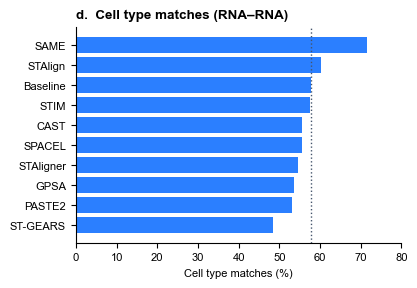

In [6]:
def bar_panel(ax, values, baseline, xlabel, xmax):
    """Horizontal bars, best method on top, with the baseline as a dotted line."""
    ax.barh(np.arange(len(values)), values.to_numpy(), height=0.8, color='#2B7FFF')
    ax.axvline(baseline, color='#45556C', linestyle=':', linewidth=1)
    ax.set_yticks(np.arange(len(values)), values.index)
    ax.set_xlim(0, xmax)
    ax.set_xlabel(xlabel)
    ax.spines[['top', 'right']].set_visible(False)


order = scores['CT matches (%)'].sort_values()
fig, ax = plt.subplots(figsize=(4.2, 2.8))
bar_panel(ax, order, scores.loc['Baseline', 'CT matches (%)'], 'Cell type matches (%)', 80)
ax.set_title('d.  Cell type matches (RNA–RNA)', loc='left', fontweight='bold')
fig.savefig(FIG_DIR / 'Fig3d_cell_type_matches.svg', bbox_inches='tight')
fig.savefig(FIG_DIR / 'Fig3d_cell_type_matches.png', dpi=300, bbox_inches='tight')
plt.show()

## 5. Fig 3e — method summary

Change in cell type (CT) and cell neighborhood (CN) matches over the baseline, in percentage points.

In [7]:
CHECK = {True: '✔', False: '✘'}
TRANSFORM_COLORS = {'Elastic': '#9AE630', 'Affine': '#51A2FF', 'Rigid': '#42D3F2',
                    'Diffeomorphic': '#FFB93B', 'Space-tearing': '#FB64B6'}


def method_table(scores, methods, columns, vmin, vmax):
    """Styled summary table: method properties and change over the baseline (percentage points)."""
    t = scores.drop('Baseline').join(methods).sort_values(['Δ CT', 'Δ CN'], ascending=False)
    cols = {('Method', ''): t.index}
    for name, col in columns:
        cols[(name, '')] = t[col]
    cols[('Required inputs', 'Expression')] = t['expression'].map(CHECK)
    cols[('Required inputs', 'Cell types')] = t['cell_types'].map(CHECK)
    cols[('Δ from baseline', 'CT matches')] = t['Δ CT']
    cols[('Δ from baseline', 'CN matches')] = t['Δ CN']
    df = pd.DataFrame(cols).reset_index(drop=True)
    delta = [('Δ from baseline', 'CT matches'), ('Δ from baseline', 'CN matches')]
    inputs = [('Required inputs', 'Expression'), ('Required inputs', 'Cell types')]
    styled = (df.style
              .map(lambda v: f'color: {"#31C950" if v == CHECK[True] else "#FF2056"}', subset=inputs)
              .background_gradient(cmap='managua', vmin=vmin, vmax=vmax, subset=delta)
              .format('{:+.2f}', subset=delta)
              .set_table_styles([
                  {'selector': 'thead th', 'props': 'background:#444;color:#fff;font-weight:700;text-align:center;'},
                  {'selector': 'td', 'props': 'padding:2px 10px;text-align:center;'},
                  {'selector': 'table', 'props': 'border-collapse:separate;border-spacing:0 4px;font-family:Arial,sans-serif;'}])
              .hide(axis='index'))
    if ('Transform', '') in df.columns:
        styled = styled.map(lambda v: f'background-color: {TRANSFORM_COLORS.get(v, "#ddd")}', subset=[('Transform', '')])
    return styled


fig3e = method_table(scores, METHODS, [('Type', 'type'), ('Transform', 'transform')], vmin=-10, vmax=10)
(FIG_DIR / 'Fig3e_method_summary.html').write_text(fig3e.to_html(), encoding='utf-8')
fig3e

## 6. Fig 3f — query cells after alignment

Query cells at their aligned positions (for SAME, at the positions of their assigned template cells). Each method
reports positions in its own coordinate frame, so panels are scaled independently.

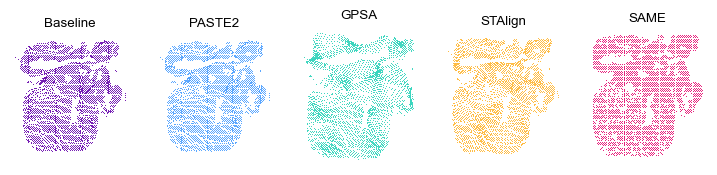

In [8]:
MAP_COLORS = {'Baseline': '#6E11B0', 'PASTE2': '#51A2FF', 'GPSA': '#38D5BE', 'STAlign': '#FFB93B', 'SAME': '#E61876'}
fig, axes = plt.subplots(1, len(MAP_COLORS), figsize=(9, 2.6))
for ax, (method, color) in zip(axes, MAP_COLORS.items()):
    xy = aligned_xy[method]
    ax.scatter(xy[:, 0], xy[:, 1], s=0.5, color=color, linewidths=0)
    ax.invert_yaxis()  # image coordinates: y down
    ax.set_aspect('equal')
    ax.set_title(method)
    ax.axis('off')
fig.savefig(FIG_DIR / 'Fig3f_aligned_query.png', dpi=300, bbox_inches='tight')
plt.show()

## 7. Fig S8 — cell neighborhoods and neighborhood matches

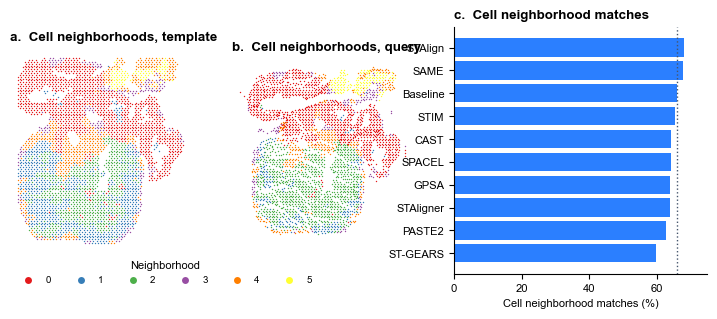

In [9]:
def neighborhood_maps(axes, xcol, ycol):
    """Cell neighborhoods on the template and query sections (initial registration)."""
    labels = sorted(set(neighborhood['template']) | set(neighborhood['query']))
    colors = dict(zip(labels, plt.get_cmap('Set1').colors))
    for ax, (name, a) in zip(axes, (('Template', template_in), ('Query', query_in))):
        lab = neighborhood[name.lower()].to_numpy()
        for l in labels:
            m = lab == l
            ax.scatter(a.obs[xcol].to_numpy()[m], a.obs[ycol].to_numpy()[m], s=1, color=colors[l], label=l, linewidths=0)
        ax.set_title(f'Cell neighborhoods, {name.lower()}', loc='left')
        ax.invert_yaxis()
        ax.set_aspect('equal')
        ax.axis('off')
    axes[0].legend(title='Neighborhood', markerscale=5, frameon=False, ncol=len(labels), loc='upper left',
                   bbox_to_anchor=(0, 0), fontsize=7)


fig, axes = plt.subplots(1, 3, figsize=(9, 3.2), gridspec_kw={'width_ratios': [1, 1, 1.4]})
neighborhood_maps(axes[:2], 'New_X', 'New_Y')
axes[0].set_title('a.  ' + axes[0].get_title(loc='left'), loc='left', fontweight='bold')
axes[1].set_title('b.  ' + axes[1].get_title(loc='left'), loc='left', fontweight='bold')
bar_panel(axes[2], scores['CN matches (%)'].sort_values(), scores.loc['Baseline', 'CN matches (%)'],
          'Cell neighborhood matches (%)', 75)
axes[2].set_title('c.  Cell neighborhood matches', loc='left', fontweight='bold')
fig.savefig(FIG_DIR / 'FigS8_cell_neighborhoods.png', dpi=300, bbox_inches='tight')
plt.show()

## 8. Check against the paper

Fig 3e and the text report a baseline of 57.7% cell type matches, 71.6% for SAME (triangle penalty = 10), 53.1% for
PASTE2 and 53.6% for GPSA.

In [10]:
PAPER_DELTA = {  # Fig 3e: (Δ CT, Δ CN)
    'SAME': (13.87, 1.91), 'STAlign': (2.51, 1.98), 'STIM': (-0.28, -0.57), 'CAST': (-2.10, -1.66),
    'SPACEL': (-2.20, -1.79), 'STAligner': (-3.23, -1.92), 'GPSA': (-4.11, -1.92), 'PASTE2': (-4.62, -3.30),
    'ST-GEARS': (-9.20, -6.06)}
got = scores.loc[list(PAPER_DELTA), ['Δ CT', 'Δ CN']].round(2)
assert np.allclose(got.to_numpy(), list(PAPER_DELTA.values())), got
assert np.allclose(scores.loc[['Baseline', 'SAME', 'PASTE2', 'GPSA'], 'CT matches (%)'].round(1), [57.7, 71.6, 53.1, 53.6])
print('All benchmark values match the paper.')

All benchmark values match the paper.
